<a href="https://colab.research.google.com/github/cpt0/Project-2/blob/main/Project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROJECT 2 - Ricardo Zavaleta

# Part 1 - Introduce the Dataset

This project uses the Facebook Metrics dataset from the UCI Machine Learning Repository at https://archive.ics.uci.edu/dataset/368/facebook+metrics.

 The data describe posts published in 2014 on the Facebook page of a well-known cosmetics brand. My target is Total Interactions, a numerical value equal to the number of comments, likes, and shares on a post.

 The predictors describe the page and the post (total page likes, post type, category, month, weekday, hour, and whether it was paid) and measure how the post performed (reach, impressions, engaged users, and consumptions, including several measures specific to people who had already liked the page).

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DATA_PATH = '/content/drive/MyDrive/DATA 201/Datasets/dataset_Facebook.csv'
fb = pd.read_csv(DATA_PATH, sep = ';')

print(fb.shape)
print(fb.head())

Mounted at /content/drive
(500, 19)
   Page total likes    Type  Category  Post Month  Post Weekday  Post Hour  \
0            139441   Photo         2          12             4          3   
1            139441  Status         2          12             3         10   
2            139441   Photo         3          12             3          3   
3            139441   Photo         2          12             2         10   
4            139441   Photo         2          12             2          3   

   Paid  Lifetime Post Total Reach  Lifetime Post Total Impressions  \
0   0.0                       2752                             5091   
1   0.0                      10460                            19057   
2   0.0                       2413                             4373   
3   1.0                      50128                            87991   
4   0.0                       7244                            13594   

   Lifetime Engaged Users  Lifetime Post Consumers  \
0             

In [3]:
fb.isna().sum()

,0
Page total likes,0
Type,0
Category,0
Post Month,0
Post Weekday,0
Post Hour,0
Paid,1
Lifetime Post Total Reach,0
Lifetime Post Total Impressions,0
Lifetime Engaged Users,0


In [4]:
cleanfb = fb.dropna()
print(cleanfb.shape)

(495, 19)


The original dataset has 500 rows and 19 columns. The target is Total Interactions. The features are Page total likes, Type, Category, Post Month, Post Weekday, Post Hour, Paid, Lifetime Post Total Reach, Lifetime Post Total Impressions, Lifetime Engaged Users, Lifetime Post Consumers, Lifetime Post Consumptions, Lifetime Post Impressions by people who have liked your Page, Lifetime Post reach by people who like your Page, and Lifetime People who have liked your Page and engaged with your post.

There were missing values in Paid (1), like (1), and share (4). I removed the rows with any missing value, which dropped 5 rows and left 495. I one-hot encoded Type, Paid, Category, Post Month, Post Weekday, and Post Hour because their values represent groups. I removed comment, like, and share from the predictors because they add up to the target, so keeping them would give the model the answer. This left 59 predictor columns after encoding. The encoding does not calculate any statistics from the data, and no scaling was needed for tree-based models.

In [18]:
fb2 = pd.get_dummies(cleanfb, columns=['Type','Paid','Category','Post Month','Post Weekday','Post Hour'], drop_first=False, dtype=int)
fb2.head()


,Page total likes,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,Lifetime Post Consumers,Lifetime Post Consumptions,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,comment,...,Post Hour_13,Post Hour_14,Post Hour_15,Post Hour_16,Post Hour_17,Post Hour_18,Post Hour_19,Post Hour_20,Post Hour_22,Post Hour_23
0,139441,2752,5091,178,109,159,3078,1640,119,4,...,0,0,0,0,0,0,0,0,0,0
1,139441,10460,19057,1457,1361,1674,11710,6112,1108,5,...,0,0,0,0,0,0,0,0,0,0
2,139441,2413,4373,177,113,154,2812,1503,132,0,...,0,0,0,0,0,0,0,0,0,0
3,139441,50128,87991,2211,790,1119,61027,32048,1386,58,...,0,0,0,0,0,0,0,0,0,0
4,139441,7244,13594,671,410,580,6228,3200,396,19,...,0,0,0,0,0,0,0,0,0,0


# Part 2 - Prepare data and fit a single tree

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [7]:
X = fb2.drop(columns=['Total Interactions','comment','like','share'])
y = fb2['Total Interactions']
# Hold out 30% of patients for testing. stratify keeps the class mix similar in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=50)


print(X_train.shape, X_test.shape)

#you can check your sets (X_train, X_test,...)
X_train.head()

(346, 59) (149, 59)


,Page total likes,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,Lifetime Post Consumers,Lifetime Post Consumptions,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,Type_Link,...,Post Hour_13,Post Hour_14,Post Hour_15,Post Hour_16,Post Hour_17,Post Hour_18,Post Hour_19,Post Hour_20,Post Hour_22,Post Hour_23
3,139441,50128,87991,2211,790,1119,61027,32048,1386,0,...,0,0,0,0,0,0,0,0,0,0
205,132201,3254,5644,371,344,513,5069,2846,283,0,...,0,0,0,0,0,0,0,0,0,0
35,138895,4512,7808,423,284,431,5183,2954,316,0,...,0,0,0,0,0,0,0,0,0,0
334,119198,10152,17099,1636,1599,2755,15382,8980,1613,0,...,0,0,0,0,0,0,0,0,0,0
55,138329,16416,31950,459,411,539,21436,9568,363,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
zuckertree = DecisionTreeRegressor(random_state=50, max_depth=None)
zuckertree.fit(X_train, y_train)

train_pred = zuckertree.predict(X_train)
test_pred = zuckertree.predict(X_test)

print('Train RMSE:', np.sqrt(mean_squared_error(y_train, train_pred)))
print('Test RMSE:', np.sqrt(mean_squared_error(y_test, test_pred)))

Train RMSE: 0.0
Test RMSE: 543.8276473912614


The single decision tree had a training RMSE of 0.00 and a test RMSE of 543.83. This is clear overfitting. With no depth limit, the tree kept splitting until it fit the training data perfectly, but its error on new posts was much higher.

# Part 3 - Build and compare a random fores

In [19]:
from sklearn.ensemble import RandomForestRegressor

faceforest = RandomForestRegressor(random_state=50, n_estimators=100, n_jobs=1)
faceforest.fit(X_train, y_train)

train2_pred = faceforest.predict(X_train)
test2_pred = faceforest.predict(X_test)

print('Train RMSE:', np.sqrt(mean_squared_error(y_train, train2_pred)))
print('Test RMSE:', np.sqrt(mean_squared_error(y_test, test2_pred)))

Train RMSE: 118.10724801925612
Test RMSE: 180.13574186330789


The random forest predicts unseen values much more accurately. Its test RMSE of 180.14 is about 67% lower than the single tree's 543.83. Although the tree had a perfect training score, it did not generalize well. The forest averages many different trees, which reduces the effect of any one tree's mistakes.

# Part 4 - Investigate two random forest parameters

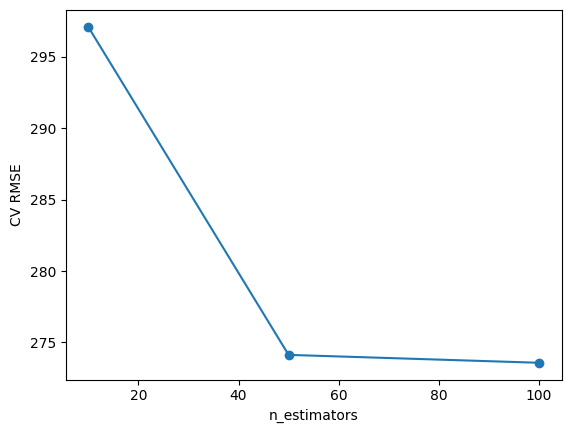

In [20]:
tree_counts = [10, 50, 100]
cv_rmse = []
for n in tree_counts:
  m = RandomForestRegressor(n_estimators=n, max_depth=None,random_state=50)
  scores = cross_val_score(m, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
  cv_rmse.append(-scores.mean())

plt.plot(tree_counts, cv_rmse, marker='o')
plt.xlabel('n_estimators')
plt.ylabel('CV RMSE')
plt.show()

Mean cross-validation RMSE was about 300 with 10 trees, 274 with 50 trees, and 273 with 100 trees. Adding trees helped a lot from 10 to 50, but going from 50 to 100 made very little difference. After a certain point, more trees mostly add computing time.

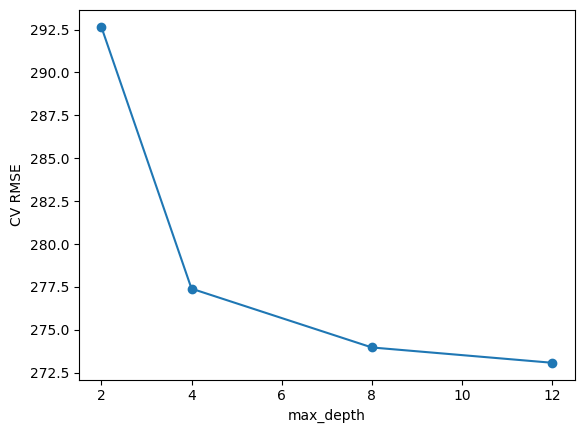

In [17]:
depths = [2,4,8,12]
cv_rmse = []
for d in depths:
    h = RandomForestRegressor(max_depth=d, n_estimators=100, random_state=50)
    scores = cross_val_score(h, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    cv_rmse.append(-scores.mean())

plt.plot(depths, cv_rmse, marker='o')
plt.xlabel('max_depth'); plt.ylabel('CV RMSE'); plt.show()

Mean cross-validation RMSE was about 292.5 at depth 2, 277.4 at depth 4, 273 at depth 8, and 273.1 at depth 12.
Smaller trees performed worse because they were too simple to capture the patterns in the data (underfitting). Performance improved quickly up to depth 8 and then mostly leveled off.

In [16]:
metaforest = RandomForestRegressor(random_state=50, n_estimators=50, max_depth=8, n_jobs=-1)
metaforest.fit(X_train, y_train)

test3_pred = metaforest.predict(X_test)
print('Test RMSE:', np.sqrt(mean_squared_error(y_test, test3_pred)))

Test RMSE: 172.7849041368389


I chose 50 trees with a maximum depth of 8. In cross-validation, 50 trees scored within about 1 RMSE point of 100 trees, and depth 8 scored within about 1 point of depth 12, so I chose the smaller, simpler settings. The final forest had a test RMSE of 172.78. This is much better than the single tree (543.83) and slightly better than the random forest (180.14).

# Part 5 - Feature importance and conclusion

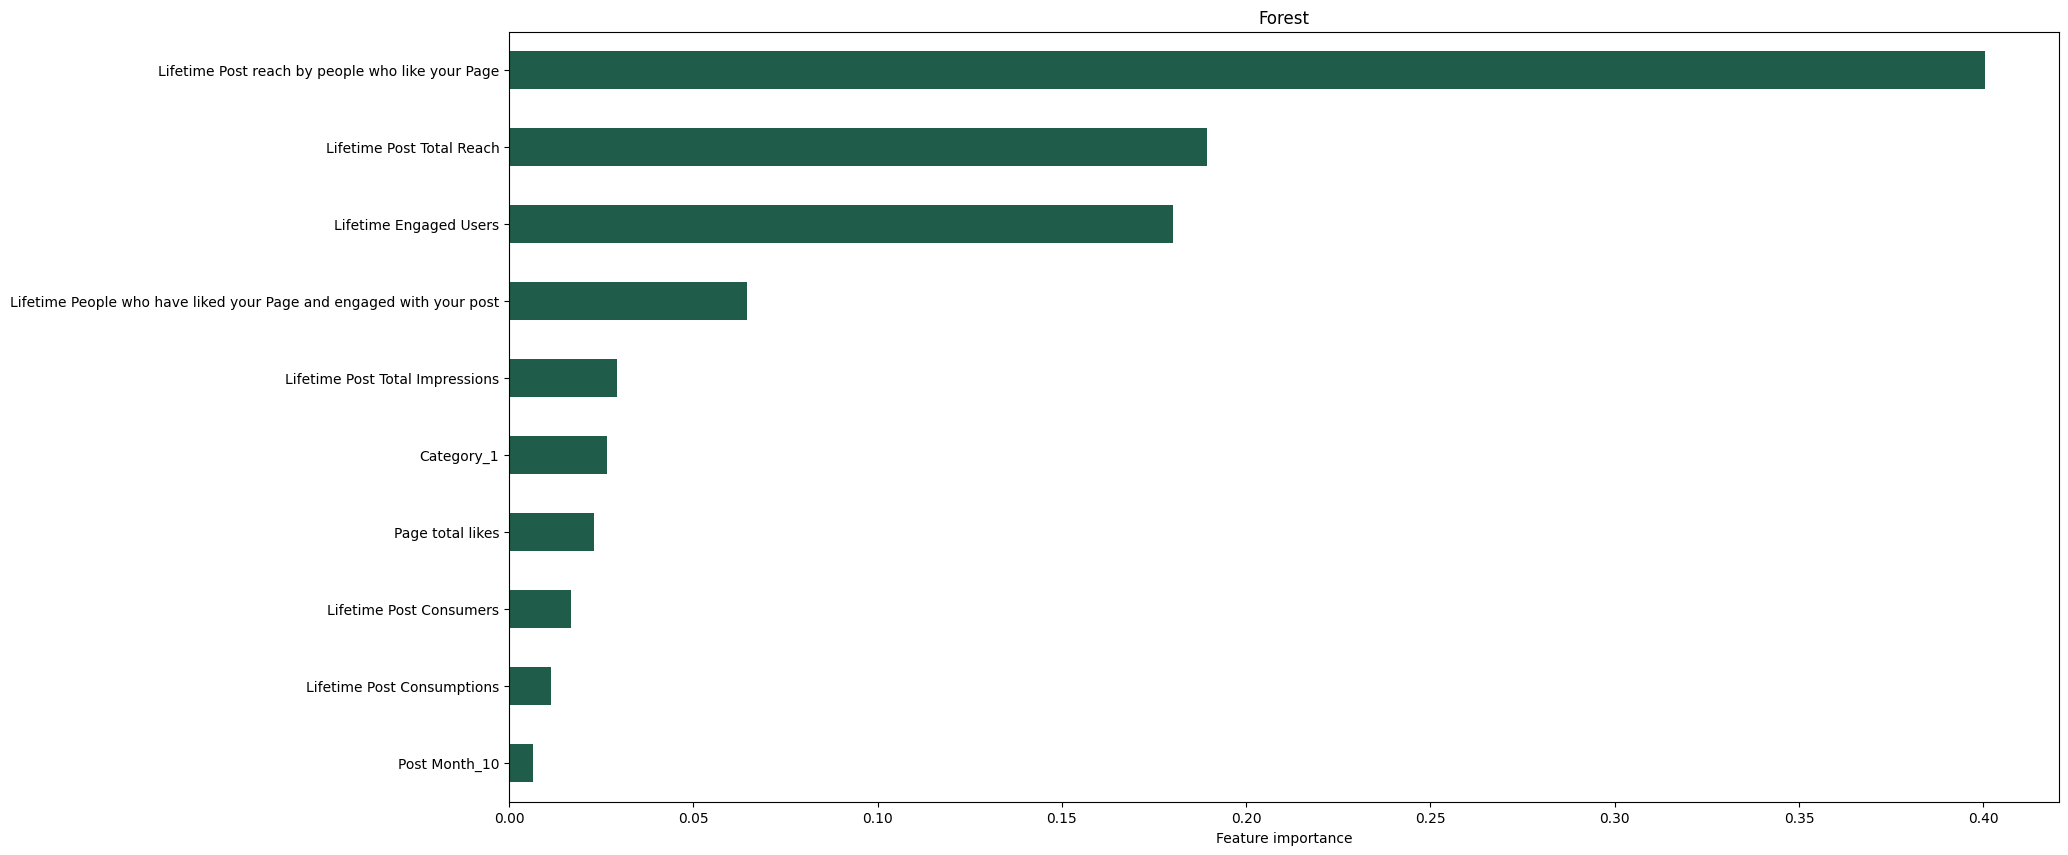

In [13]:
imp = pd.Series(metaforest.feature_importances_, index=X.columns).sort_values()

imp[imp > 0].tail(10).plot(kind='barh', figsize=(20, 10), color='#1F5C4A')
plt.xlabel('Feature importance'); plt.title('Forest'); plt.show()

#.tail allows us to only show 10 features.

The three most important predictors were:

Lifetime Post reach by people who like your Page (about 0.40): the number of unique page followers who saw the post. Followers already have an interest in the brand, so reaching more of them may go along with more likes, comments, and shares.

Lifetime Post Total Reach (about 0.19): the number of unique people who saw the post. The more people see a post, the more chances it has to get interactions.

Lifetime Engaged Users (about 0.18): the number of unique people who clicked on the post in any way. People who click are already paying attention, so they may be more likely to interact.

Feature importance shows what the model relied on to make predictions. It does not prove that these features cause more interactions.

# Conclusion

I predicted the total number of interactions on a cosmetics brand's Facebook posts. The final random forest, with 50 trees and a maximum depth of 8, performed best with a test RMSE of 172.78, compared with 180.14 for the original forest and 543.83 for the single tree. Adding trees and allowing more depth both improved cross-validation performance at first, but the gains became very small after 50 trees and a depth of 8. One limitation is that many important predictors, such as reach and engaged users, are only known after a post is published, so this model cannot forecast a new post's success in advance. The data also come from only one brand in one year, so the results may not apply to other pages.